# 02 · Shares, growth rates (CAGR) and crossovers

**Questions**
1. How fast has each energy source grown, and how does *growth rate* compare with *absolute growth*?
2. How have the shares of fossil, renewable and low-carbon sources changed?
3. When did solar, wind and other renewables overtake hydropower?

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.energy import *
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ej = pd.read_csv("../data/processed/tes_by_source_EJ.csv", index_col="year")
ej.columns.name = "source"

## 1. Definitions (written down before computing anything)
| Group | Sources | Notes |
|---|---|---|
| **Renewables** | Hydropower + Solar, wind & other renewables + Biofuels & waste | IEA TES definition |
| **Modern renewables** | Hydropower + Solar, wind & other renewables | Excludes biofuels & waste, which includes traditional biomass |
| **Fossil** | Coal + Natural gas + Oil | |
| **Low-carbon** | Renewables + Nuclear | |

**Why two renewable definitions?** In this data, *Biofuels and waste* includes traditional use of biomass for cooking and heating, a large part of energy supply in many developing countries that is not the "energy transition" most people mean. Reporting both shows whether the headline result depends on that choice.

**Accounting-method caveat:** TES shares depend on how non-combustible sources are counted (IEA uses a physical energy content method; other publishers use a substitution method). Shares here are not directly comparable to figures from other sources. Check the IEA documentation for the edition used.

## 2. Shares

In [2]:
sh = shares(ej)
grp = pd.DataFrame({
    "Fossil": group_share(ej, FOSSIL),
    "Renewables": group_share(ej, RENEWABLES),
    "Modern renewables": group_share(ej, MODERN_REN),
    "Low-carbon (incl. nuclear)": group_share(ej, LOW_CARBON),
})
print("Shares of total energy supply (%)")
grp.loc[[1990, 2000, 2010, 2020, 2024]]

Shares of total energy supply (%)


,Fossil,Renewables,Modern renewables,Low-carbon (incl. nuclear)
year,,,,
1990,81.81,12.15,2.54,18.19
2000,81.14,12.05,2.87,18.86
2010,82.73,11.63,3.19,17.27
2020,80.73,14.24,5.23,19.27
2024,80.46,14.79,6.07,19.54


In [3]:
a, b = grp.loc[1990], grp.loc[2024]
for k in grp.columns:
    print(f"{k:28s} {a[k]:5.1f}% -> {b[k]:5.1f}%   ({b[k]-a[k]:+.1f} percentage points)")

Fossil                        81.8% ->  80.5%   (-1.3 percentage points)
Renewables                    12.1% ->  14.8%   (+2.6 percentage points)
Modern renewables              2.5% ->   6.1%   (+3.5 percentage points)
Low-carbon (incl. nuclear)    18.2% ->  19.5%   (+1.3 percentage points)


## 3. CAGR, done correctly
$$\text{CAGR}=\left(\frac{V_{end}}{V_{start}}\right)^{1/n}-1$$
`n` is the number of annual **intervals**: 1990→2024 is **34**, not 35. (35 is the number of data points.) I also compute CAGR over sub-periods, because one 34-year number hides acceleration.

In [4]:
windows = [(1990, 2024), (1990, 2000), (2000, 2010), (2010, 2024)]
cg = cagr_table(ej, windows)
cg

,1990-2024,1990-2000,2000-2010,2010-2024
Coal and coal products,1.95,0.40,4.68,1.14
Natural gas,2.26,2.21,2.84,1.87
Hydropower,2.19,2.03,2.81,1.86
Nuclear,1.00,2.54,0.62,0.17
"Solar, wind and other renewables",8.34,5.04,6.17,12.37
Biofuels and waste,1.43,0.87,1.66,1.66
Oil and oil products,1.08,1.29,1.22,0.82
Total supply,1.72,1.33,2.52,1.42


In [5]:
# Sanity check: CAGR must reproduce the end value when compounded
for c in ej.columns:
    r = cagr(ej.loc[1990, c], ej.loc[2024, c], 34)
    assert np.isclose(ej.loc[1990, c] * (1 + r) ** 34, ej.loc[2024, c])
print("CAGR round-trip check passed for all sources")

CAGR round-trip check passed for all sources


## 4. Growth *rate* vs *absolute* growth
A high CAGR from a tiny base can still be small in absolute terms. Comparing both avoids overstating the transition.

In [6]:
delta = (ej.loc[2024] - ej.loc[1990]).rename("Added 1990→2024 (EJ)")
tab = pd.concat([delta, cg["1990-2024"].rename("CAGR 1990–2024 (%)"),
                 (delta / delta.sum() * 100).rename("Share of all added supply (%)")], axis=1)
tab = tab.drop(index="Total supply")      # keep sources only; total growth is reported separately
tab = tab.assign(**{"Share of all added supply (%)": tab["Added 1990→2024 (EJ)"] / tab["Added 1990→2024 (EJ)"].sum() * 100})
tab.sort_values("Added 1990→2024 (EJ)", ascending=False)

,Added 1990→2024 (EJ),CAGR 1990–2024 (%),Share of all added supply (%)
Coal and coal products,86.17,1.95,30.20
Natural gas,79.03,2.26,27.70
Oil and oil products,59.47,1.08,20.84
"Solar, wind and other renewables",21.81,8.34,7.64
Biofuels and waste,21.65,1.43,7.59
Nuclear,8.81,1.00,3.09
Hydropower,8.39,2.19,2.94


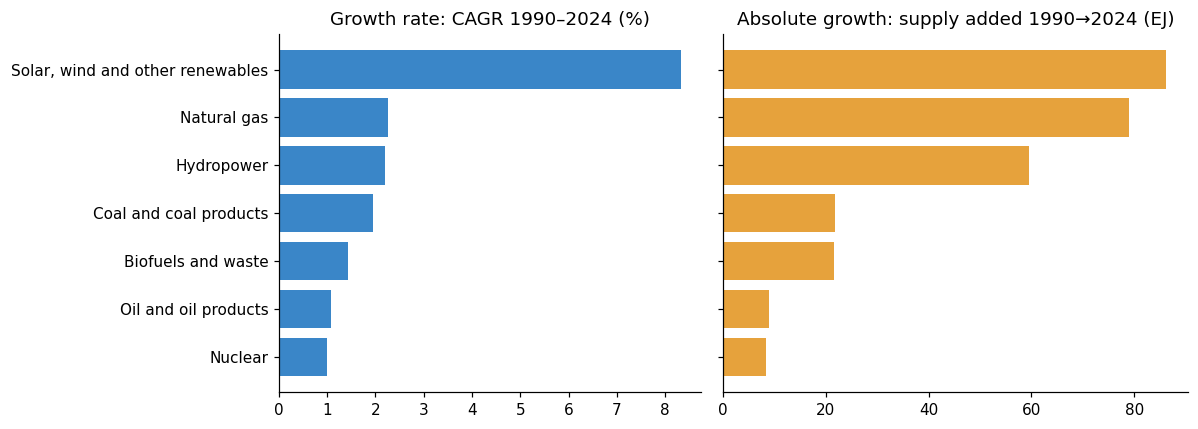

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.1]})
t = tab.sort_values("CAGR 1990–2024 (%)")
axes[0].barh(t.index, t["CAGR 1990–2024 (%)"], color="#3a86c8")
axes[0].set(title="Growth rate: CAGR 1990–2024 (%)")
t2 = tab.sort_values("Added 1990→2024 (EJ)")
axes[1].barh(t2.index, t2["Added 1990→2024 (EJ)"], color="#e6a23c")
axes[1].set(title="Absolute growth: supply added 1990→2024 (EJ)"); axes[1].set_yticklabels([])
plt.tight_layout(); fig.savefig("../figures/02_cagr_vs_absolute.png", dpi=160); plt.show()

## 5. When did solar, wind & other renewables overtake hydropower?
A crossover is the first year after which A stays above B (so a one-year blip would not count).

In [8]:
def crossover_year(a, b):
    diff = (ej[a] - ej[b])
    above = diff > 0
    for yr in ej.index:
        if above.loc[yr:].all():
            return int(yr)
    return None

swo, hyd = "Solar, wind and other renewables", "Hydropower"
x = crossover_year(swo, hyd)
print(f"{swo} permanently exceeds {hyd} from {x}")
print("Gap (EJ) around the crossover:", (ej[swo] - ej[hyd]).loc[x-2:x+1].round(2).to_dict())

# Other pairs worth knowing
pairs = [(swo, "Nuclear"), (swo, "Biofuels and waste"), ("Natural gas", "Coal and coal products"),
         (hyd, "Nuclear")]
for a_, b_ in pairs:
    y = crossover_year(a_, b_)
    print(f"{a_} > {b_}:", y if y else "not (yet)")

Solar, wind and other renewables permanently exceeds Hydropower from 2021
Gap (EJ) around the crossover: {2019: -2.12, 2020: -1.02, 2021: 1.0, 2022: 2.99}
Solar, wind and other renewables > Nuclear: not (yet)
Solar, wind and other renewables > Biofuels and waste: not (yet)
Natural gas > Coal and coal products: not (yet)
Hydropower > Nuclear: not (yet)


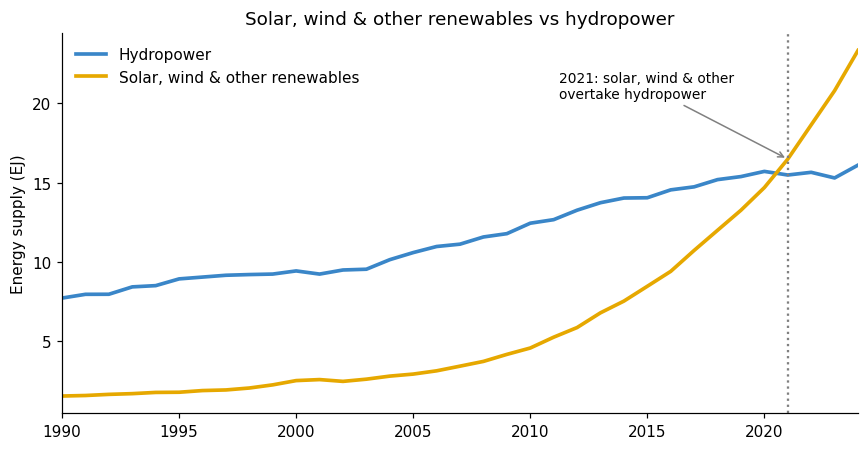

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ej.index, ej[hyd], color="#3a86c8", lw=2.4, label="Hydropower")
ax.plot(ej.index, ej[swo], color="#e6a800", lw=2.4, label="Solar, wind & other renewables")
ax.axvline(x, color="grey", ls=":")
ax.annotate(f"{x}: solar, wind & other\novertake hydropower", (x, ej.loc[x, swo]), xytext=(-150, 40),
            textcoords="offset points", arrowprops=dict(arrowstyle="->", color="grey"), fontsize=9)
ax.set(title="Solar, wind & other renewables vs hydropower", ylabel="Energy supply (EJ)", xlim=(1990, 2024))
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); fig.savefig("../figures/03_crossover_swo_vs_hydro.png", dpi=160); plt.show()

> **Wording note:** the IEA category is *Solar, wind and other renewables* (it also includes geothermal, solar thermal, etc.), so claims should say "solar, wind and other renewables", not "solar/wind" alone.

## 6. The share story

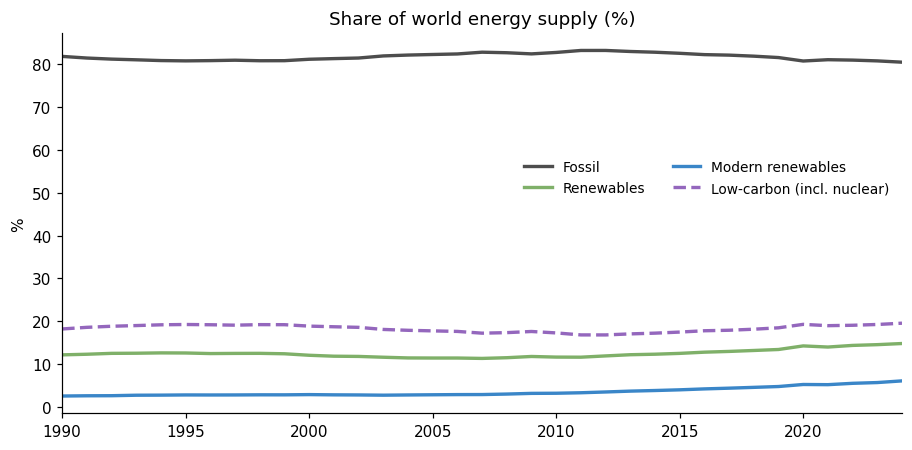

In [10]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
styles = {"Fossil": ("#4d4d4d", "-"), "Renewables": ("#7fb069", "-"),
          "Modern renewables": ("#3a86c8", "-"), "Low-carbon (incl. nuclear)": ("#9467bd", "--")}
for k, (c, ls) in styles.items():
    ax.plot(grp.index, grp[k], color=c, ls=ls, lw=2.2, label=k)
ax.set(title="Share of world energy supply (%)", ylabel="%", xlim=(1990, 2024))
ax.legend(frameon=False, fontsize=9, ncol=2, loc="center right", bbox_to_anchor=(1, 0.62))
plt.tight_layout(); fig.savefig("../figures/04_group_shares.png", dpi=160); plt.show()

## 7. Save results

In [11]:
grp.to_csv("../results/group_shares_pct.csv")
sh.to_csv("../results/source_shares_pct.csv")
cg.to_csv("../results/cagr_by_window_pct.csv")
tab.to_csv("../results/growth_rate_vs_absolute.csv")
print("saved")

saved
